# 1. Load dataset và đếm số lượng ảnh và label

In [1]:
yaml_content = """
path: /kaggle/input/datasets/mementomoriml/water-meters/water_meters

train: images/train
val: images/val
test: images/test

names:
  0: reading_region
"""

with open("/kaggle/working/data.yaml", "w") as f:
    f.write(yaml_content)

print("Đã tạo file data.yaml tại /kaggle/working/")

Đã tạo file data.yaml tại /kaggle/working/


In [2]:
import os
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
!pip install ultralytics
from ultralytics import YOLO
import pandas as pd
import random
import math
import torch
import ultralytics.utils.loss as loss_module
import ultralytics.utils.metrics as metrics_module

DATASET_PATH = Path("/kaggle/input/datasets/mementomoriml/water-meters/water_meters")

split = ["train", "val", "test"]

for s in split:
    img_dir = DATASET_PATH / "images" / s
    label_dir = DATASET_PATH / "labels" / s
    
    print(f"Số lượng ảnh trong tập {s}: {len(list(img_dir.glob('*.*')))}")
    print(f"Số lượng label trong tập {s}: {len(list(label_dir.glob('*.txt')))}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Số lượng ảnh trong tập train: 995
Số lượng label trong tập train: 995
Số lượng ảnh trong tập val: 124
Số lượng label trong tập val: 124
Số lượng ảnh trong tập test: 125
Số lượng label trong tập test: 125


# 2. Trực quan hóa dữ liệu với polygon

/kaggle/input/datasets/mementomoriml/water-meters/water_meters/labels/train/id_896_value_102_623.txt


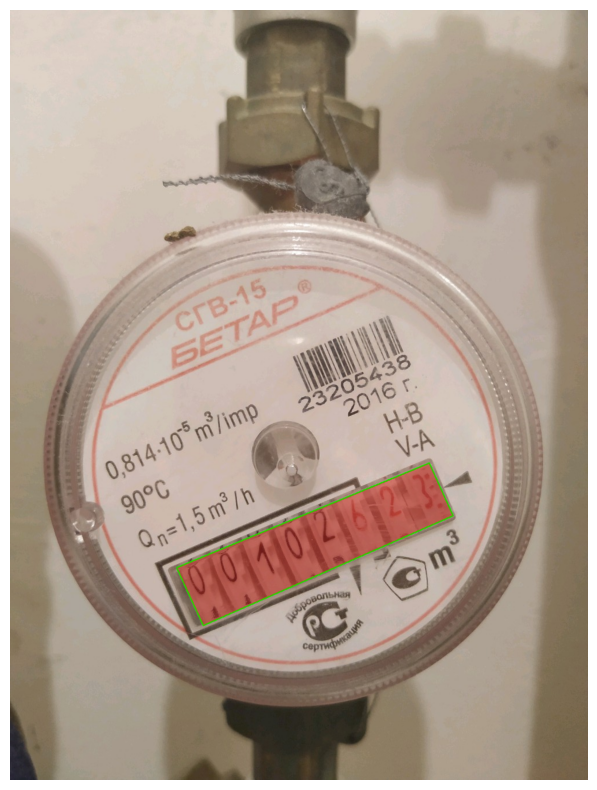

In [3]:
img_path = DATASET_PATH / "images" / "train"
label_path = DATASET_PATH / "labels" / "train"

img_dir = list(img_path.glob("*.*"))

img_file = img_dir[0]
img_0 = cv2.imread(str(img_file))
img_rgb = cv2.cvtColor(img_0, cv2.COLOR_BGR2RGB)
h, w, _ = img_rgb.shape

label_file = label_path / f"{img_file.stem}.txt"
print(label_file)

with open(label_file, "r") as f:
    lines = f.readlines()

for line in lines:
        parts = list(map(float, line.strip().split()))
        if len(parts) > 1:
            class_id = int(parts[0])
            coords = parts[1:]
            
            points = []
            for i in range(0, len(coords), 2):
                x = int(coords[i] * w)
                y = int(coords[i+1] * h)
                points.append([x, y])
            
            pts = np.array(points, np.int32).reshape((-1, 1, 2))
            
            cv2.polylines(img_rgb, [pts], isClosed=True, color=(0, 255, 0), thickness=2)
            
            overlay = img_rgb.copy()
            cv2.fillPoly(overlay, [pts], color=(255, 0, 0)) # Màu đỏ mờ
            img_rgb = cv2.addWeighted(overlay, 0.3, img_rgb, 0.7, 0)

plt.figure(figsize=(10, 10))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

# 3. Huấn luyện mô hình

In [4]:
import math
import torch
import ultralytics.utils.loss as loss_module
import ultralytics.utils.metrics as metrics_module

def inner_siou(box1, box2, xywh=True, GIoU=False, DIoU=False, CIoU=True, eps=1e-7, ratio=1.15):
    if xywh:
        (x1, y1, w1, h1), (x2, y2, w2, h2) = box1.chunk(4, -1), box2.chunk(4, -1)
        w1_, h1_, w2_, h2_ = w1 / 2, h1 / 2, w2 / 2, h2 / 2
        b1_x1, b1_x2, b1_y1, b1_y2 = x1 - w1_, x1 + w1_, y1 - h1_, y1 + h1_
        b2_x1, b2_x2, b2_y1, b2_y2 = x2 - w2_, x2 + w2_, y2 - h2_, y2 + h2_
    else:
        b1_x1, b1_y1, b1_x2, b1_y2 = box1.chunk(4, -1)
        b2_x1, b2_y1, b2_x2, b2_y2 = box2.chunk(4, -1)
        w1, h1 = (b1_x2 - b1_x1).clamp(0), (b1_y2 - b1_y1 + eps).clamp(0)
        w2, h2 = (b2_x2 - b2_x1).clamp(0), (b2_y2 - b2_y1 + eps).clamp(0)
        x1, y1 = (b1_x1 + b1_x2) / 2, (b1_y1 + b1_y2) / 2
        x2, y2 = (b2_x1 + b2_x2) / 2, (b2_y1 + b2_y2) / 2
        w1_, h1_, w2_, h2_ = w1 / 2, h1 / 2, w2 / 2, h2 / 2

    inter = (torch.min(b1_x2, b2_x2) - torch.max(b1_x1, b2_x1)).clamp(0) *             (torch.min(b1_y2, b2_y2) - torch.max(b1_y1, b2_y1)).clamp(0)
    union = w1 * h1 + w2 * h2 - inter + eps
    iou = inter / union

    inner_b1_x1, inner_b1_x2 = x1 - w1_ * ratio, x1 + w1_ * ratio
    inner_b1_y1, inner_b1_y2 = y1 - h1_ * ratio, y1 + h1_ * ratio
    inner_b2_x1, inner_b2_x2 = x2 - w2_ * ratio, x2 + w2_ * ratio
    inner_b2_y1, inner_b2_y2 = y2 - h2_ * ratio, y2 + h2_ * ratio

    inner_inter = (torch.min(inner_b1_x2, inner_b2_x2) - torch.max(inner_b1_x1, inner_b2_x1)).clamp(0) *                   (torch.min(inner_b1_y2, inner_b2_y2) - torch.max(inner_b1_y1, inner_b2_y1)).clamp(0)
    inner_union = (w1 * ratio) * (h1 * ratio) + (w2 * ratio) * (h2 * ratio) - inner_inter + eps
    inner_iou = inner_inter / inner_union

    cw = torch.max(b1_x2, b2_x2) - torch.min(b1_x1, b2_x1) + eps
    ch = torch.max(b1_y2, b2_y2) - torch.min(b1_y1, b2_y1) + eps
    s_cw = (b2_x1 + b2_x2 - b1_x1 - b1_x2) * 0.5 + eps
    s_ch = (b2_y1 + b2_y2 - b1_y1 - b1_y2) * 0.5 + eps
    sigma = torch.pow(s_cw ** 2 + s_ch ** 2, 0.5) + eps
    sin_alpha_1 = torch.abs(s_cw) / sigma
    sin_alpha_2 = torch.abs(s_ch) / sigma
    threshold = pow(2, 0.5) / 2
    sin_alpha = torch.where(sin_alpha_1 > threshold, sin_alpha_2, sin_alpha_1)
    sin_alpha = torch.clamp(sin_alpha, -1.0 + eps, 1.0 - eps)
    angle_cost = torch.cos(torch.arcsin(sin_alpha) * 2 - math.pi / 2)
    rho_x = (s_cw / cw) ** 2
    rho_y = (s_ch / ch) ** 2
    gamma = angle_cost - 2
    distance_cost = 2 - torch.exp(gamma * rho_x) - torch.exp(gamma * rho_y)
    omiga_w = torch.abs(w1 - w2) / torch.max(w1, w2)
    omiga_h = torch.abs(h1 - h2) / torch.max(h1, h2)
    shape_cost = torch.pow(1 - torch.exp(-1 * omiga_w), 4) + torch.pow(1 - torch.exp(-1 * omiga_h), 4)

    return inner_iou - 0.5 * (distance_cost + shape_cost)

loss_module.bbox_iou = inner_siou
metrics_module.bbox_iou = inner_siou


In [5]:
model = YOLO("yolo11n-seg.pt")

results = model.train(
    data='data.yaml', 
    epochs=100, 
    batch=16, 
    workers=4, 


    # --- Tối ưu hóa lỗi Background (Bkg) ---
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    mosaic=1.0,
    mixup=0.1,   
    
    # --- Phép biến đổi khác ---
    scale=0.3,
    fliplr=0.5,
    flipud=0.5,
    erasing=0.05,
    copy_paste=0,
    close_mosaic=15,
    
    # --- Hyperparameters ---
    warmup_epochs=5,
    weight_decay=0.0005,
    patience=30,
    lr0=0.001,
    lrf=0.1,
    cos_lr=True,
    optimizer="AdamW"
)


Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.05, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, overlap

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      3.23G     0.9457      1.216     0.8211     0.9657          0          7        640: 100% ━━━━━━━━━━━━ 63/63 4.9it/s 12.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.0it/s 1.4s
                   all        124        124      0.896      0.935      0.966      0.746      0.921      0.903      0.956      0.695

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
      3/100      3.24G     0.9325      1.135     0.7834     0.9636          0          6        640: 100% ━━━━━━━━━━━━ 63/63 4.9it/s 12.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.8it/s 1.4s
                   all        124        124      0.961      0.879      0.946      0.749      0.973      0.882      0.945      0.685

      Epoch    G

# 4. Trực quan hóa kết quả


📊 Training Results:
   🎯 mAP50: 0.9950
   🎯 mAP50-95: 0.9384
   🎯 Precision: 0.9994
   🎯 Recall: 0.9919
   📦 Box loss: 0.3537
   🏷️  Cls loss: 0.2417
   🎯 DFL loss: 0.7732


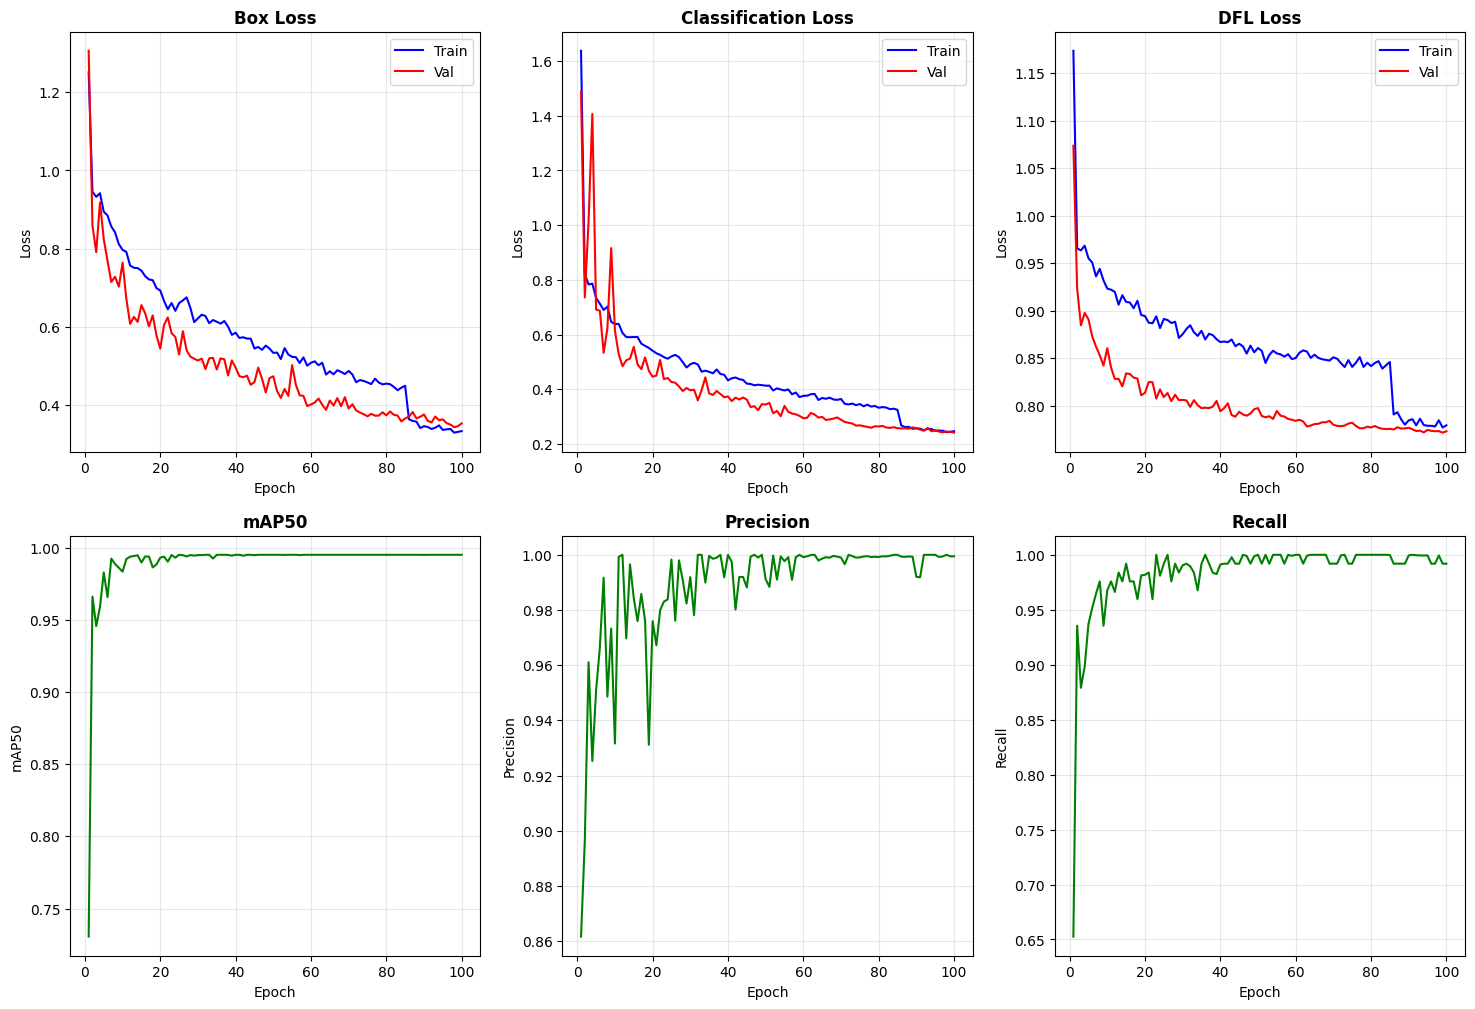

In [6]:
def visualize_training_loss(results_path):
    results_csv = Path(results_path) / "results.csv"
    df = pd.read_csv(results_csv)
    last_row = df.iloc[-1]
    final_metrics = {
            'mAP50': last_row.get('metrics/mAP50(B)', 0),
            'mAP50_95': last_row.get('metrics/mAP50-95(B)', 0),
            'precision': last_row.get('metrics/precision(B)', 0),
            'recall': last_row.get('metrics/recall(B)', 0),
            'box_loss': last_row.get('val/box_loss', 0),
            'cls_loss': last_row.get('val/cls_loss', 0),
            'dfl_loss': last_row.get('val/dfl_loss', 0)
        }
    
    # In kết quả cuối cùng
    print(f"\n📊 Training Results:")
    print(f"   🎯 mAP50: {final_metrics['mAP50']:.4f}")
    print(f"   🎯 mAP50-95: {final_metrics['mAP50_95']:.4f}")
    print(f"   🎯 Precision: {final_metrics['precision']:.4f}")
    print(f"   🎯 Recall: {final_metrics['recall']:.4f}")
    print(f"   📦 Box loss: {final_metrics['box_loss']:.4f}")
    print(f"   🏷️  Cls loss: {final_metrics['cls_loss']:.4f}")
    print(f"   🎯 DFL loss: {final_metrics['dfl_loss']:.4f}")

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    metrics = [
        ('train/box_loss', 'val/box_loss', 'Box Loss'),
        ('train/cls_loss', 'val/cls_loss', 'Classification Loss'),
        ('train/dfl_loss', 'val/dfl_loss', 'DFL Loss')
    ]
    for idx, (train_metric, val_metric, title) in enumerate(metrics):
        ax = axes[0, idx]
        if train_metric in df.columns:
            ax.plot(df['epoch'], df[train_metric], label='Train', color='blue')
        if val_metric in df.columns:
            ax.plot(df['epoch'], df[val_metric], label='Val', color='red')
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.legend()
        ax.grid(True, alpha=0.3)
    metric_plots = [
        ('metrics/mAP50(B)', 'mAP50'),
        ('metrics/precision(B)', 'Precision'),
        ('metrics/recall(B)', 'Recall')
    ]
    
    for idx, (metric, title) in enumerate(metric_plots):
        ax = axes[1, idx]
        if metric in df.columns:
            ax.plot(df['epoch'], df[metric], color='green')
            ax.set_title(title, fontweight='bold')
            ax.set_xlabel('Epoch')
            ax.set_ylabel(title)
            ax.grid(True, alpha=0.3)
    plt.show()
    return final_metrics

final_metrics = visualize_training_loss('/kaggle/working/runs/segment/train')

# 5. Trực quan hóa biểu đồ confusion matrix và ROC

--- Confusion Matrix ---


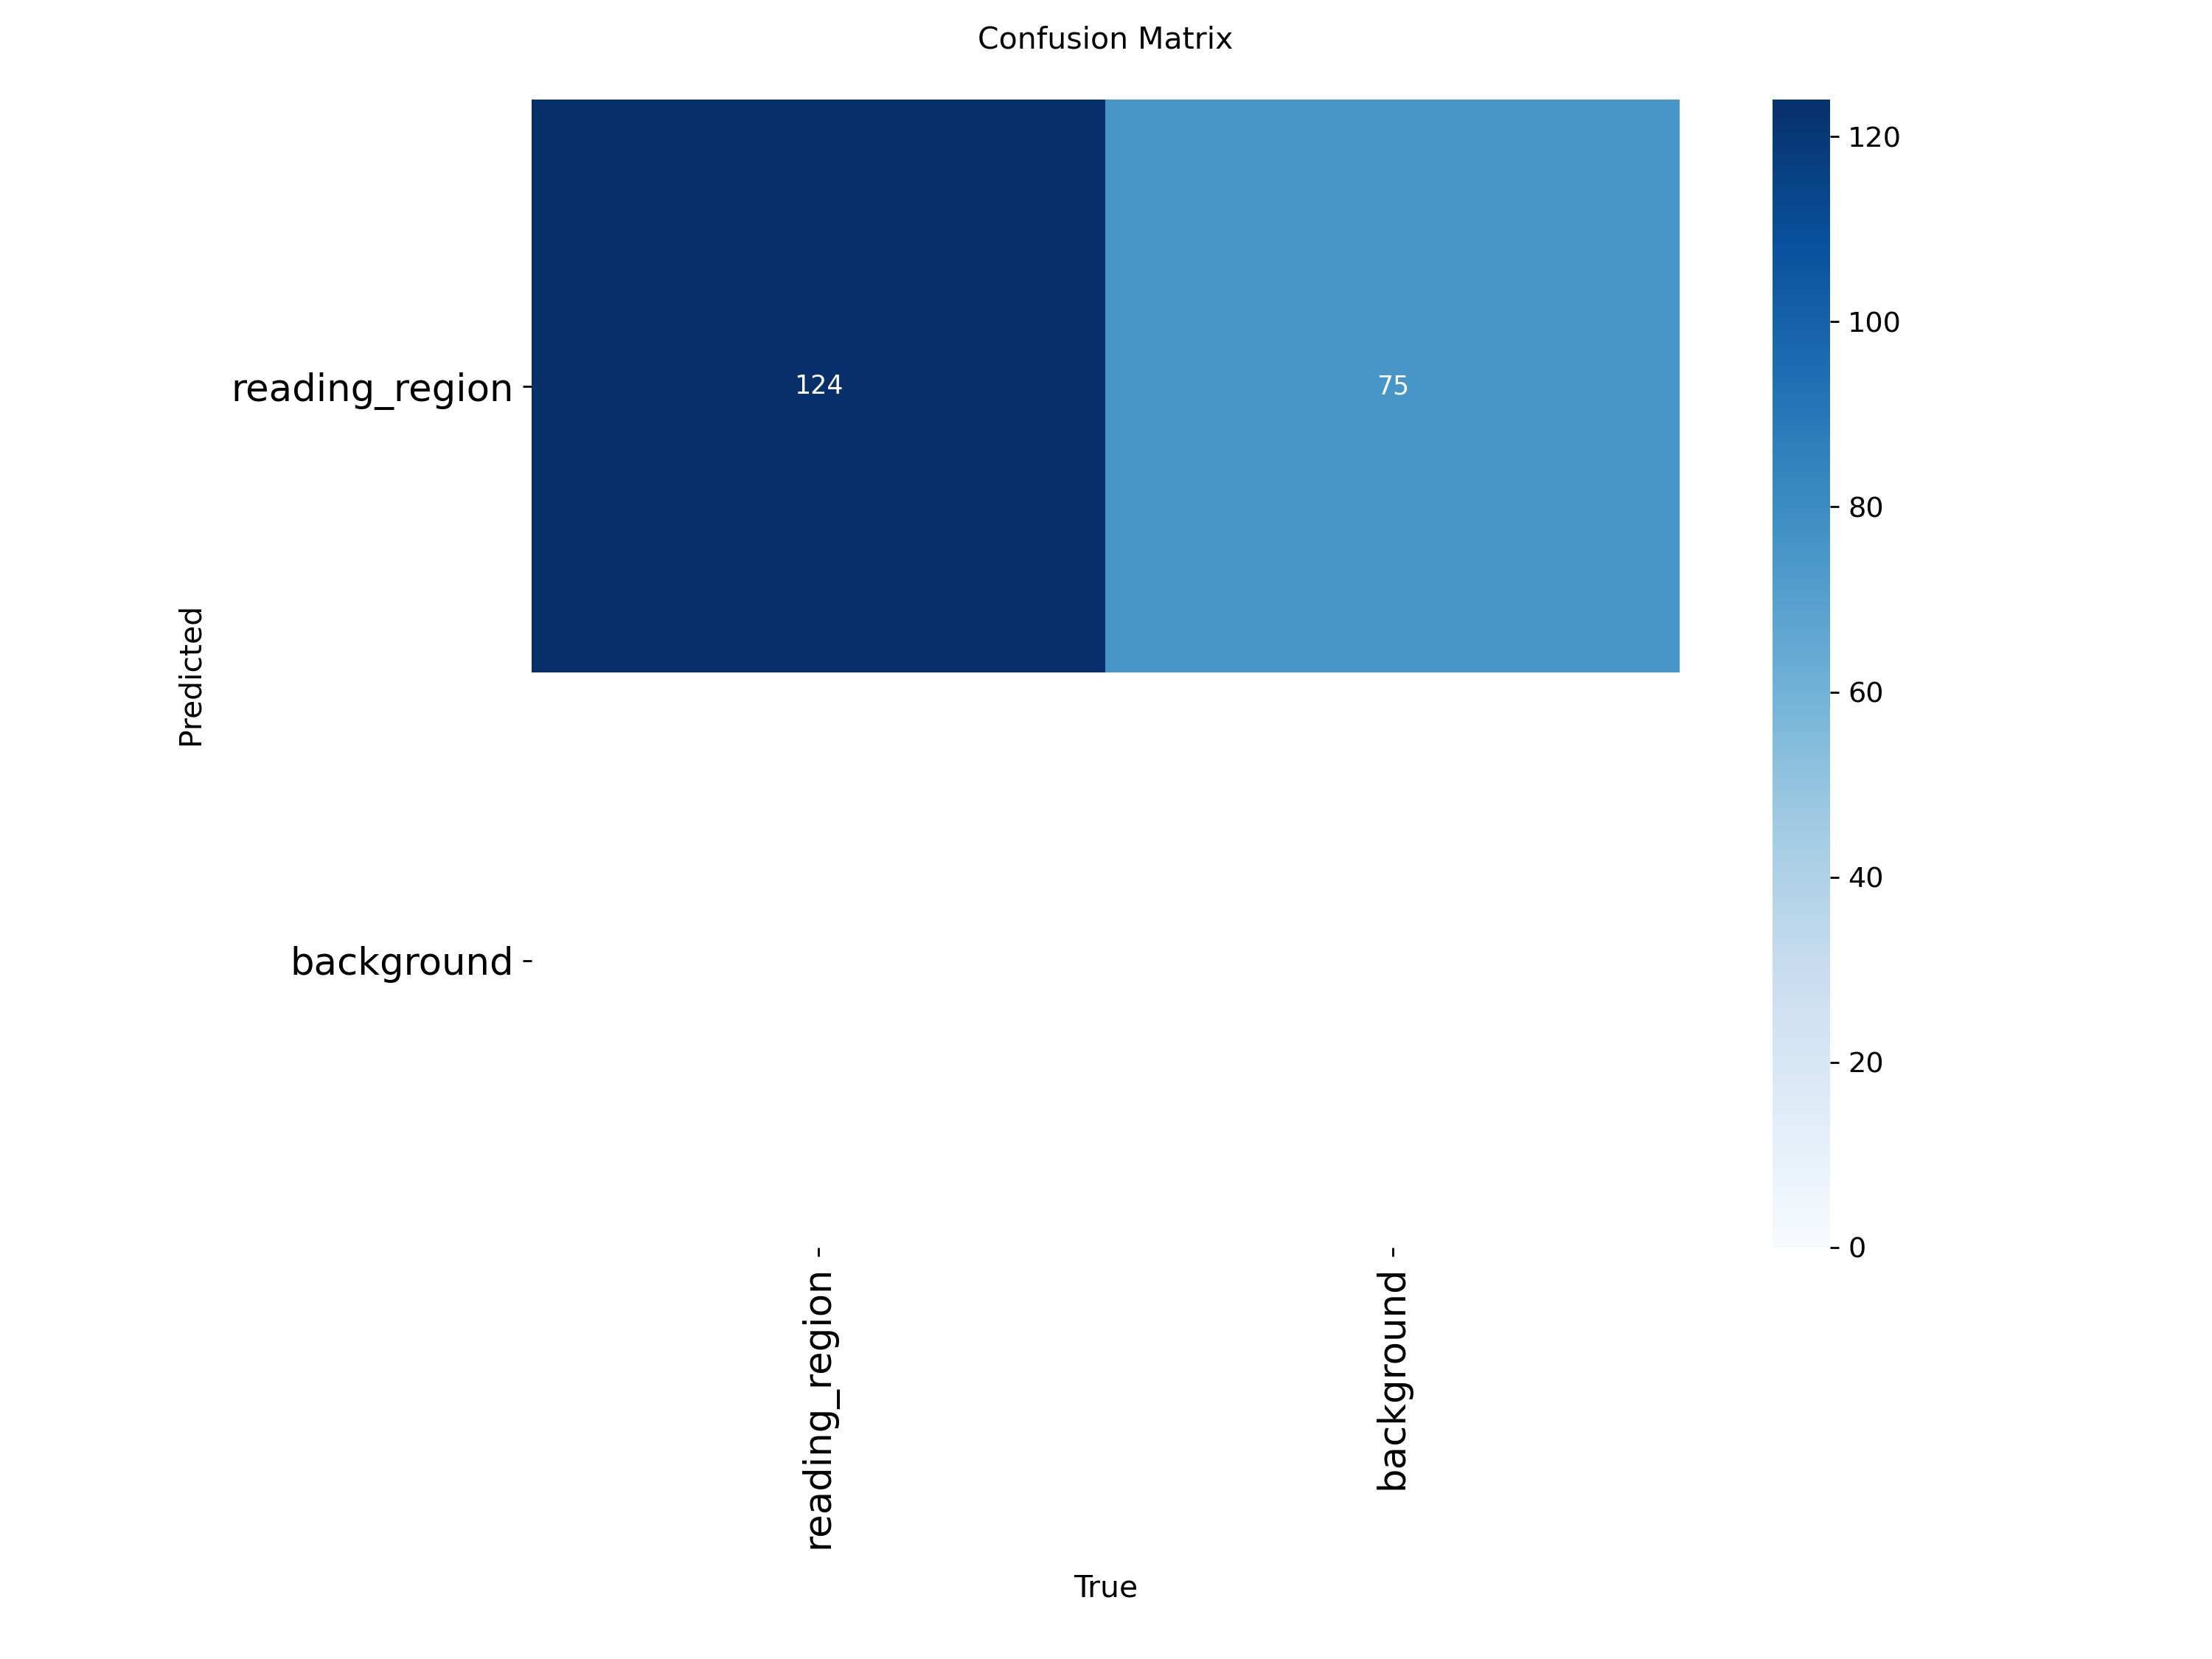

--- PR Curve ---


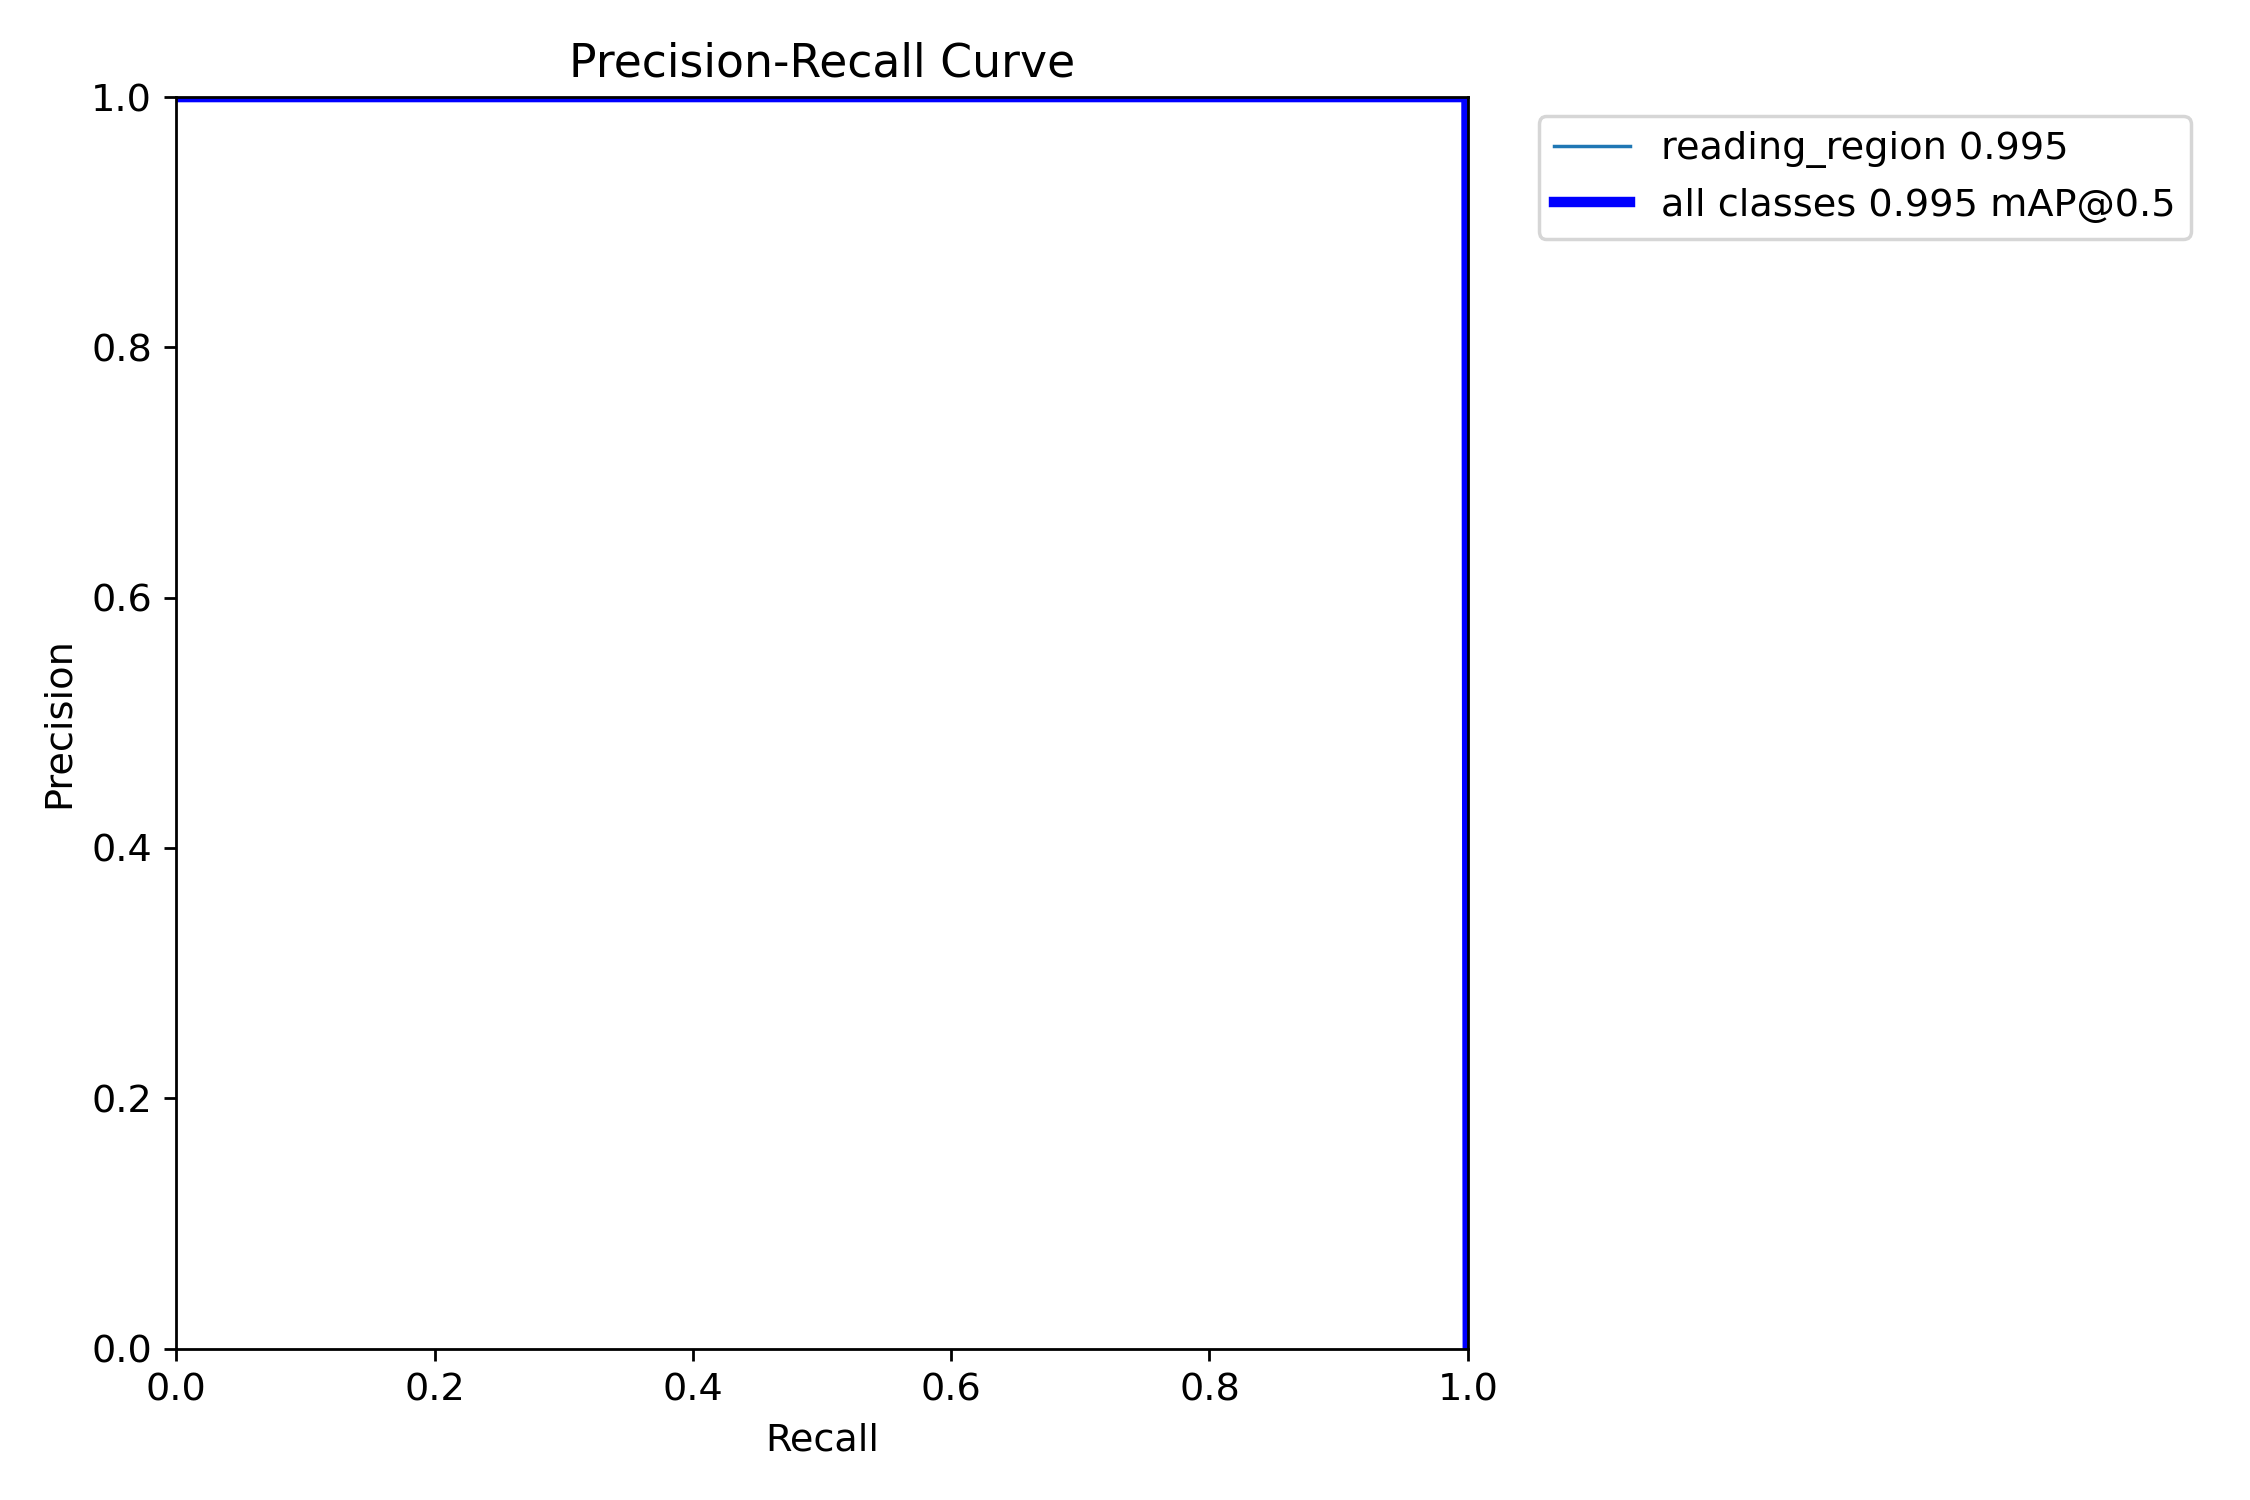

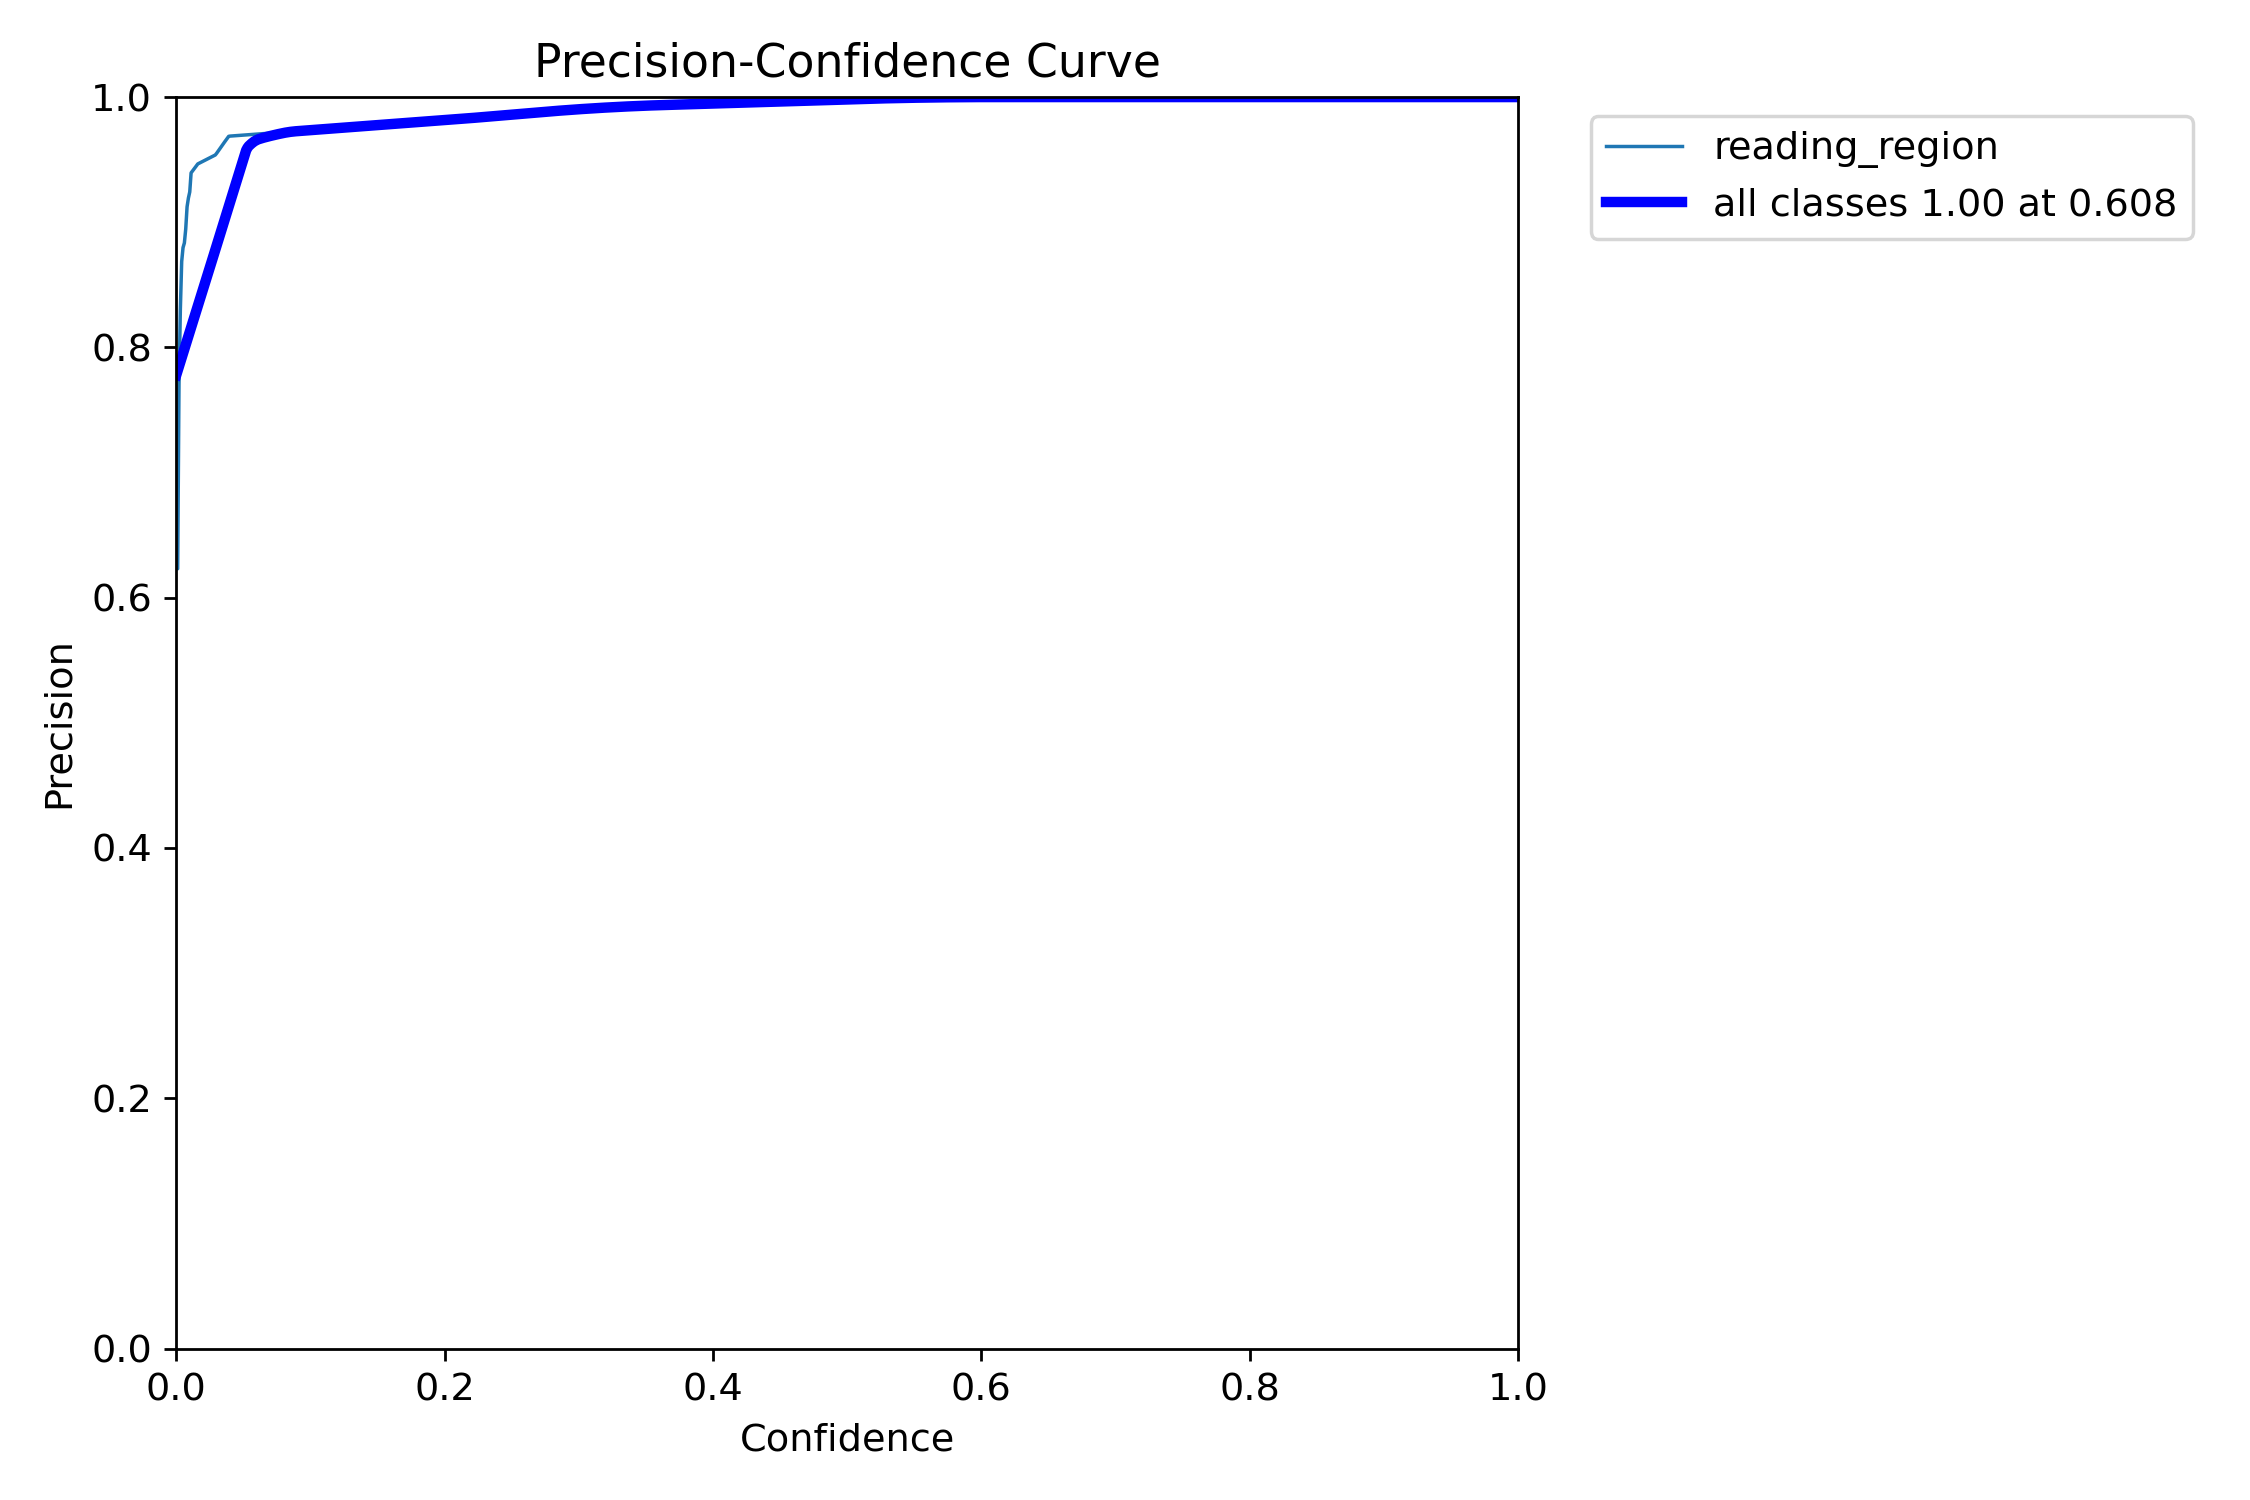

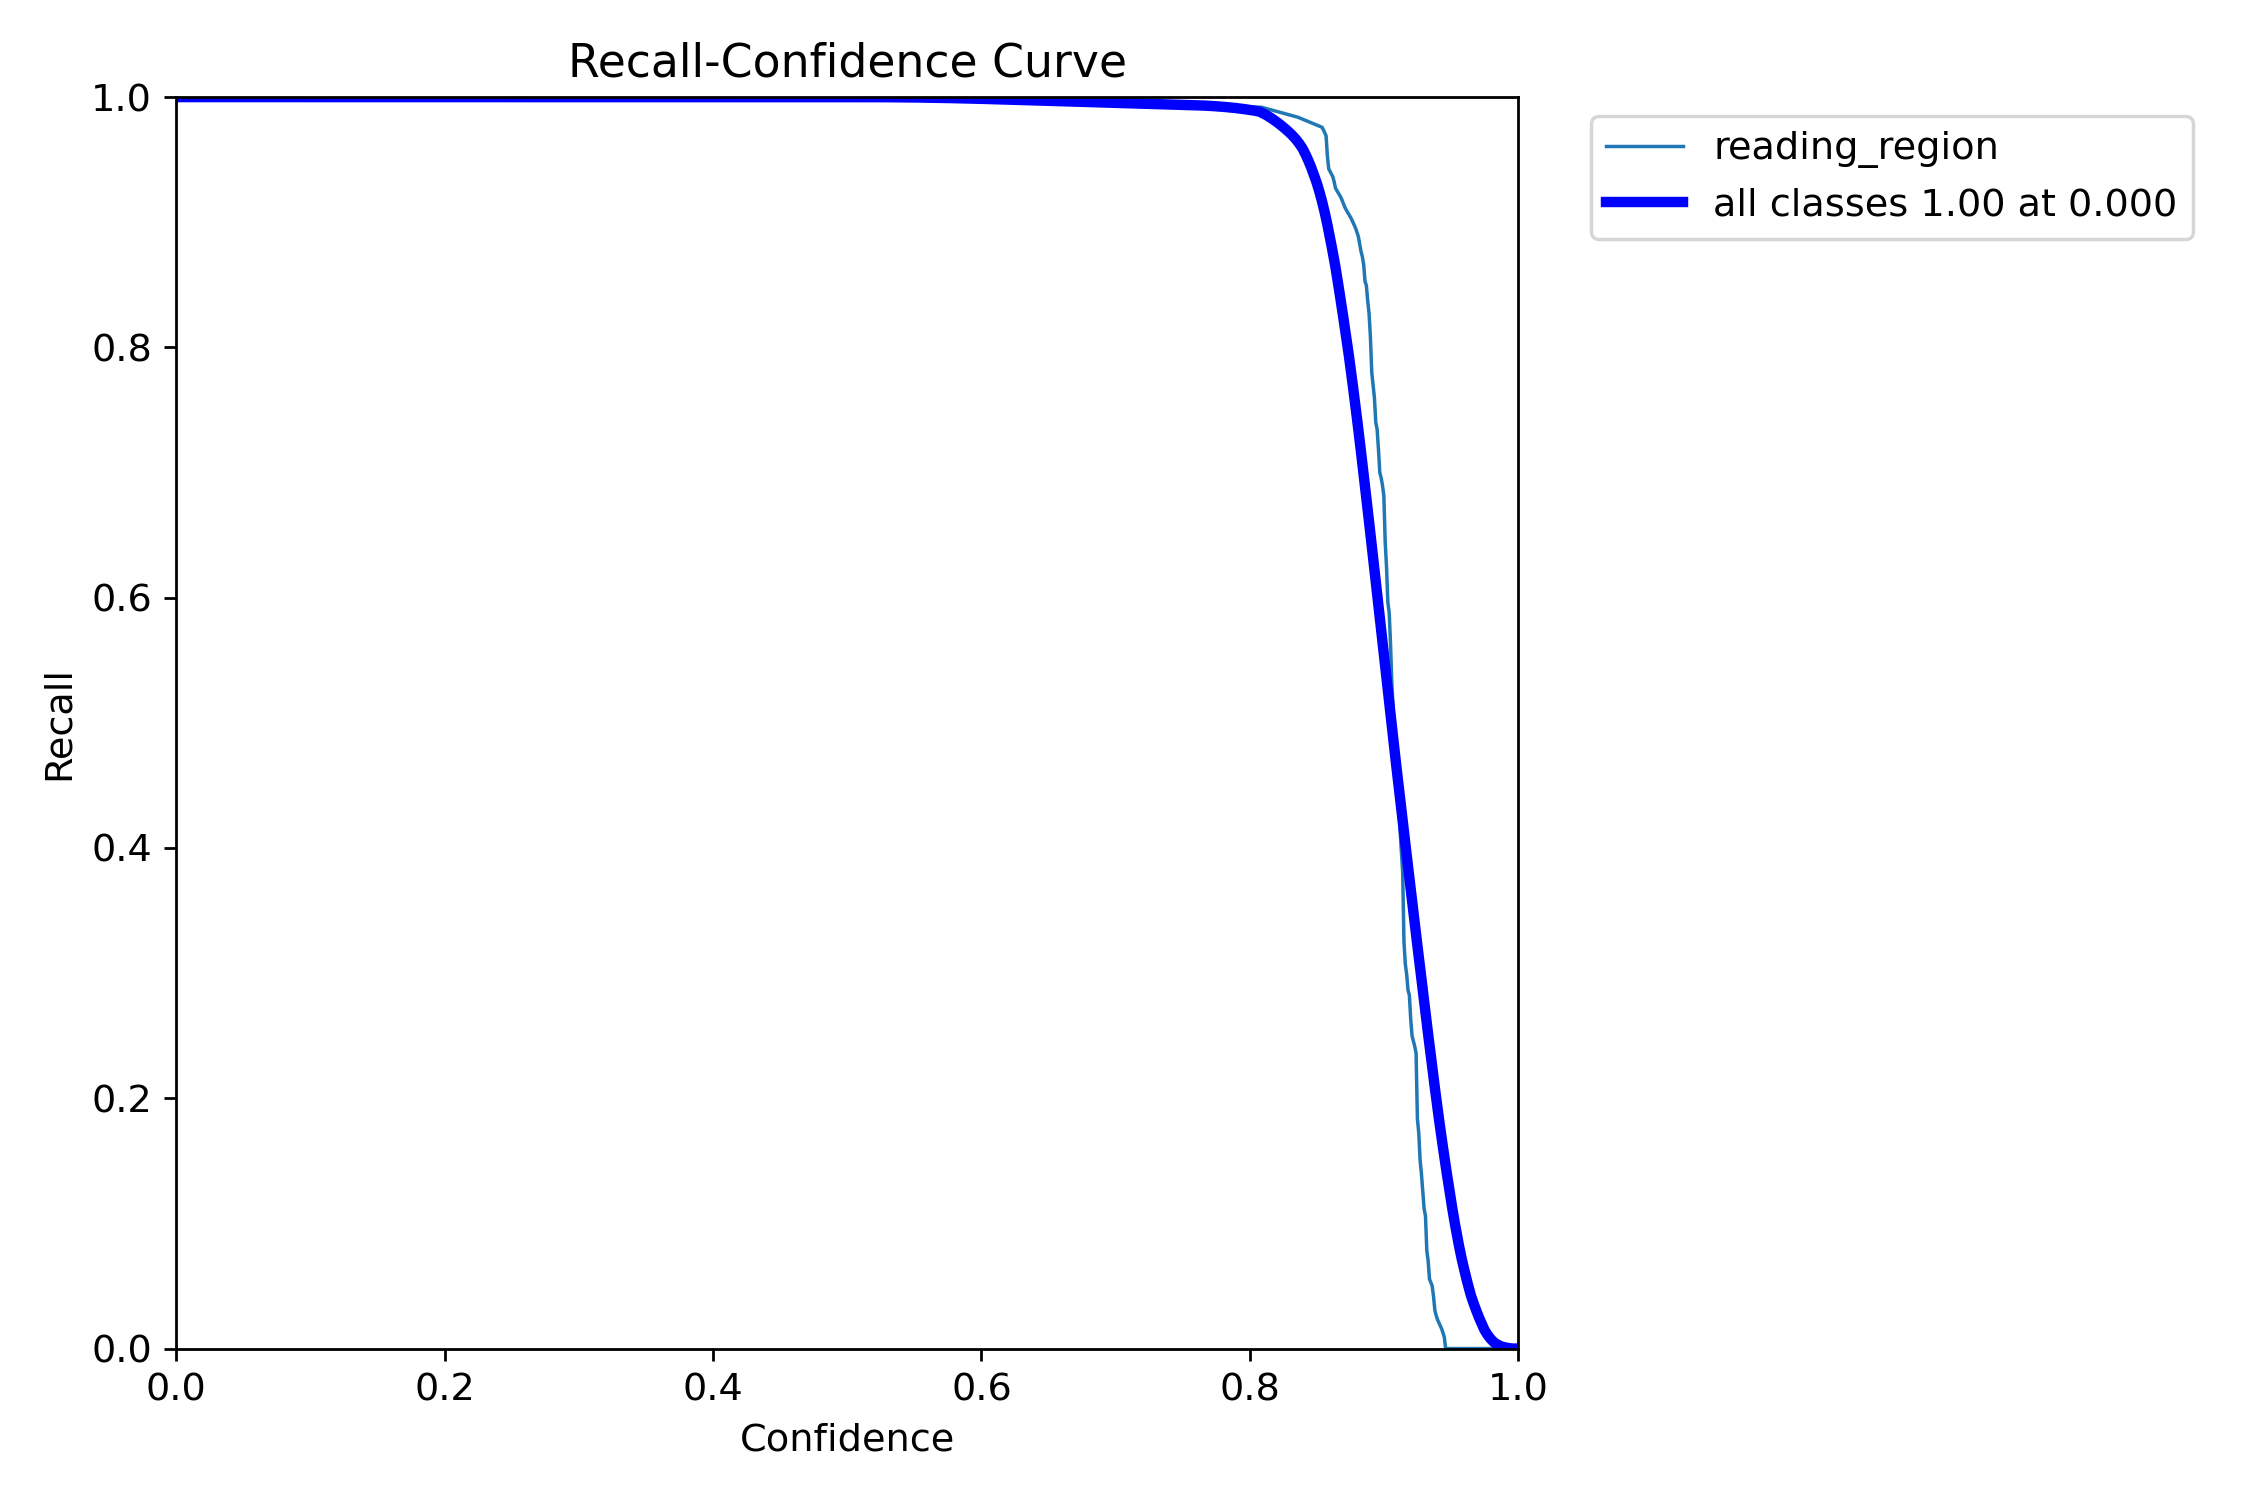

--- Loss & Metrics (Results) ---


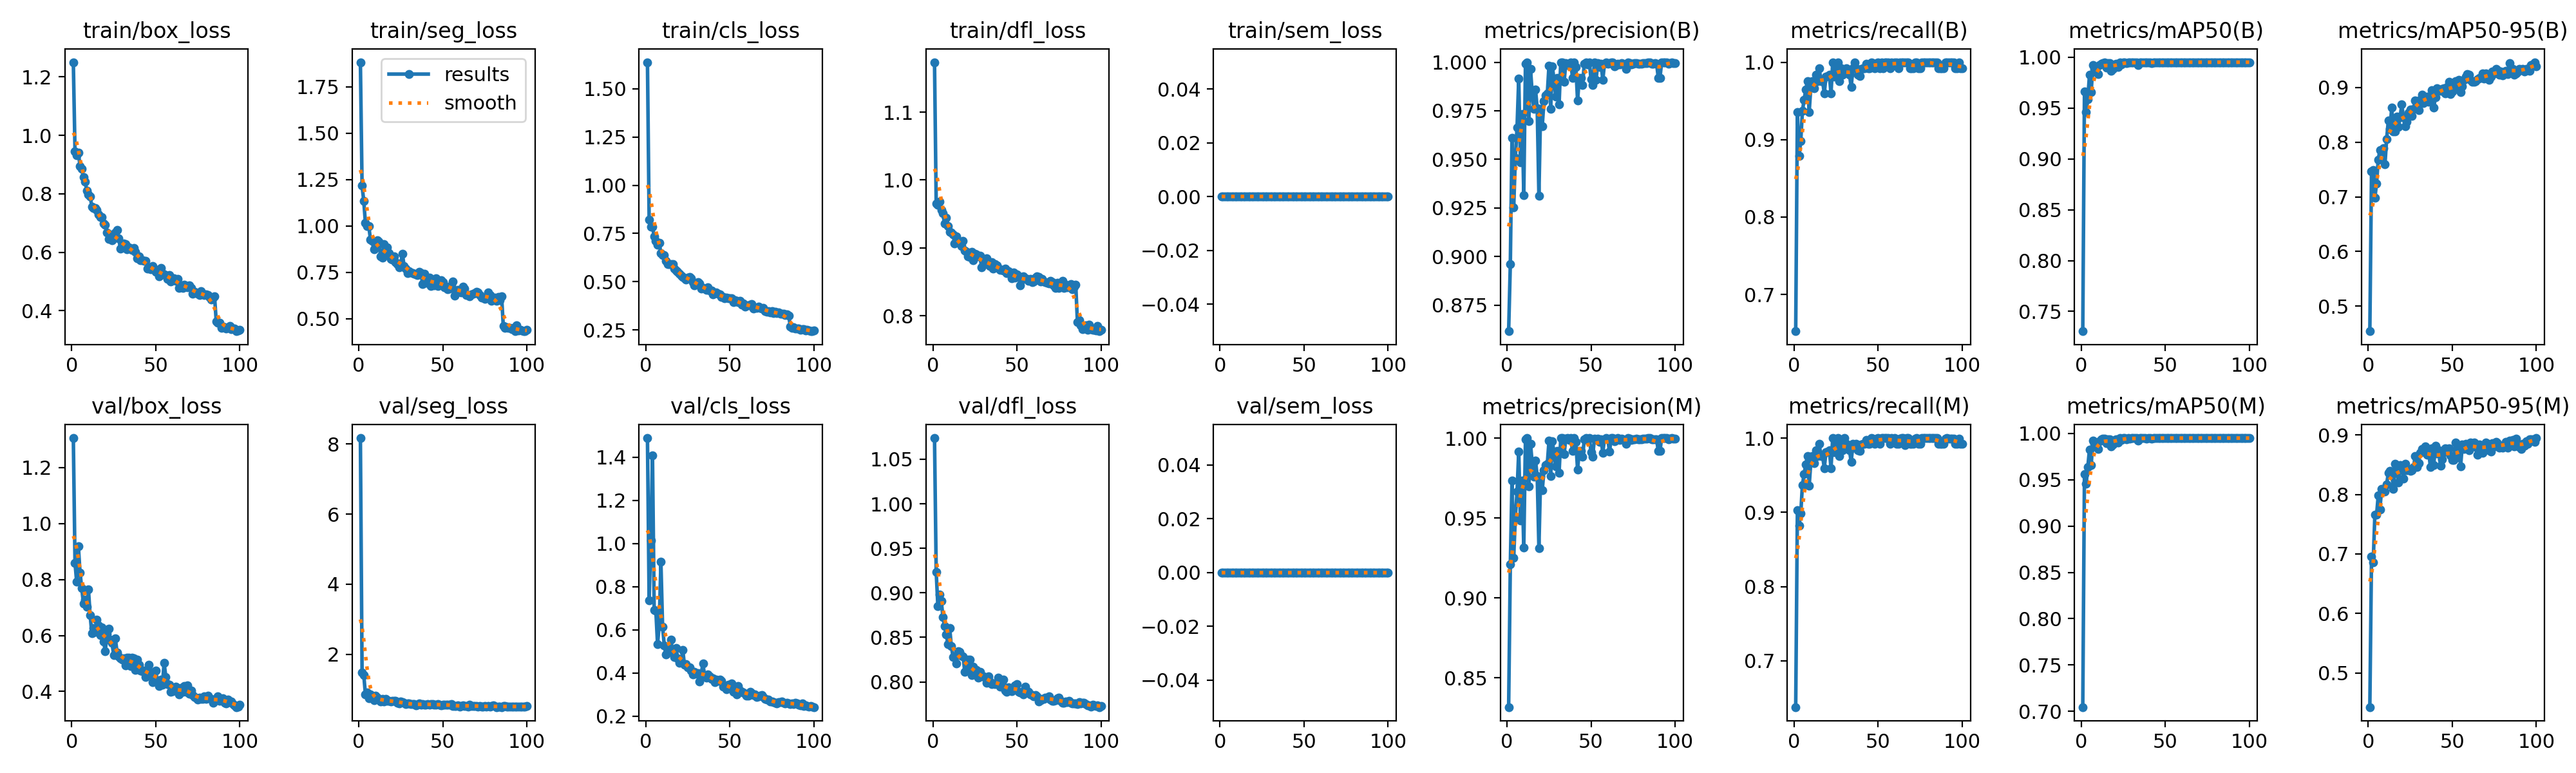

In [7]:
from IPython.display import Image, display

# Đường dẫn tới thư mục train
folder_path = '/kaggle/working/runs/segment/train/'

print("--- Confusion Matrix ---")
display(Image(filename=folder_path + 'confusion_matrix.png', width=1000))
print("--- PR Curve ---")
display(Image(filename=folder_path + 'BoxPR_curve.png', width=1000))
display(Image(filename=folder_path + 'BoxP_curve.png', width=1000))
display(Image(filename=folder_path + 'BoxR_curve.png', width=1000))

print("--- Loss & Metrics (Results) ---")
display(Image(filename=folder_path + 'results.png', width=1000))

# 6. Dự đoán

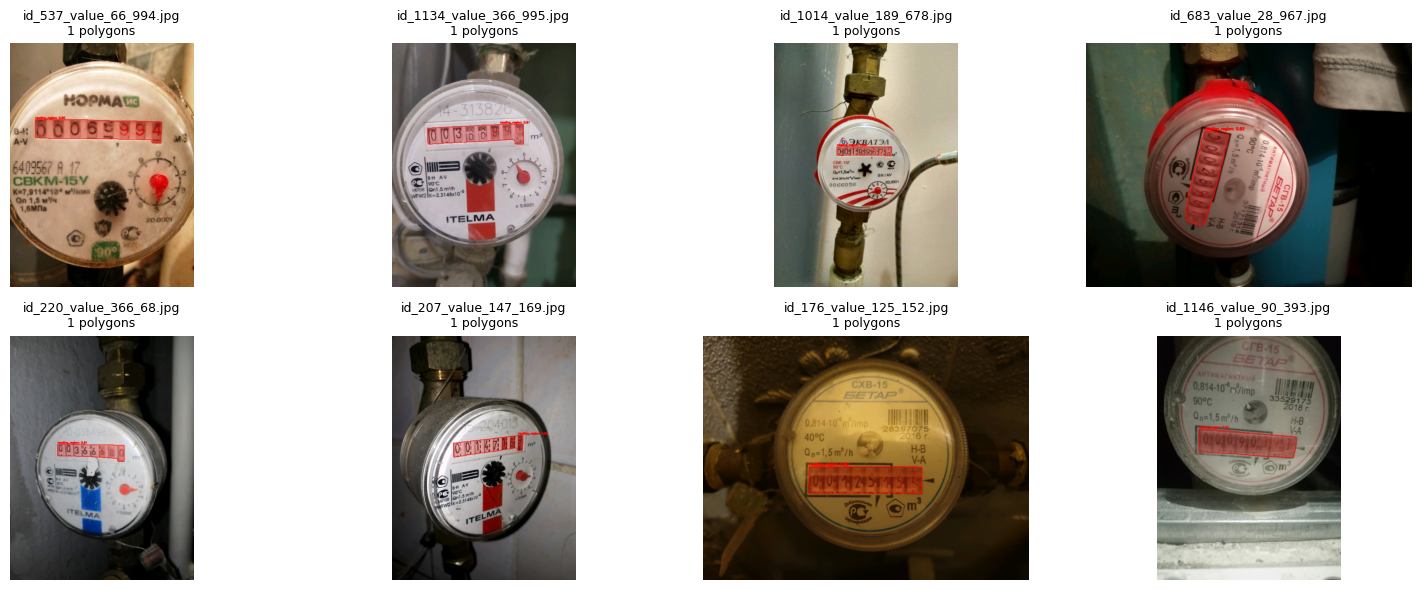


Detection Summary:
   Images: 8
   Polygons: 8
   Average per image: 1.0
   Average confidence: 0.910
   Max confidence: 0.927

Class Distribution:
   reading_region: 8


In [8]:
from collections import Counter

def predict_and_visualize(model_path, test_images_dir, num_samples=8, conf_threshold=0.5):
    model = YOLO(model_path)
    test_path = Path(test_images_dir)
    image_extensions = {".jpg", ".jpeg", ".png"}
    image_files = sorted(
        p for p in test_path.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    )

    if not image_files:
        raise FileNotFoundError(f"Không tìm thấy ảnh trong: {test_path}")

    random.seed(42)
    image_files = random.sample(image_files, min(num_samples, len(image_files)))

    cols = min(4, len(image_files))
    rows = (len(image_files) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3))
    axes = np.atleast_1d(axes).flatten()

    total_detections = 0
    class_counts = Counter()
    confidences = []

    for idx, img_path in enumerate(image_files):
        ax = axes[idx]
        img = cv2.imread(str(img_path))

        if img is None:
            ax.set_title(f"Không đọc được: {img_path.name}")
            ax.axis("off")
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        results = model.predict(str(img_path), conf=conf_threshold, verbose=False)
        result = results[0]
        detections = 0

        if result.masks is not None and result.boxes is not None:
            polygons = result.masks.xy
            boxes = result.boxes

            for polygon, box in zip(polygons, boxes):
                detections += 1
                total_detections += 1

                cls_id = int(box.cls[0].cpu().item())
                conf = float(box.conf[0].cpu().item())
                confidences.append(conf)
                class_counts[cls_id] += 1

                color = tuple(
                    int(channel * 255)
                    for channel in plt.cm.hsv(cls_id / max(len(model.names), 1))[:3]
                )
                polygon = np.asarray(polygon, dtype=np.int32).reshape((-1, 1, 2))

                overlay = img_rgb.copy()
                cv2.fillPoly(overlay, [polygon], color=color)
                img_rgb = cv2.addWeighted(overlay, 0.25, img_rgb, 0.75, 0)
                cv2.polylines(
                    img_rgb,
                    [polygon],
                    isClosed=True,
                    color=color,
                    thickness=2,
                )

                class_name = model.names.get(cls_id, str(cls_id))
                x_text, y_text = polygon[0, 0]
                cv2.putText(
                    img_rgb,
                    f"{class_name}: {conf:.2f}",
                    (int(x_text), max(int(y_text) - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    color,
                    2,
                    cv2.LINE_AA,
                )

        ax.imshow(img_rgb)
        ax.set_title(f"{img_path.name}\n{detections} polygons", fontsize=9)
        ax.axis("off")

    for idx in range(len(image_files), len(axes)):
        axes[idx].axis("off")

    plt.tight_layout()
    plt.show()

    print("\nDetection Summary:")
    print(f"   Images: {len(image_files)}")
    print(f"   Polygons: {total_detections}")
    print(f"   Average per image: {total_detections / len(image_files):.1f}")
    print(
        f"   Average confidence: {np.mean(confidences):.3f}"
        if confidences else "   Average confidence: N/A"
    )
    print(
        f"   Max confidence: {np.max(confidences):.3f}"
        if confidences else "   Max confidence: N/A"
    )

    print("\nClass Distribution:")
    for cls_id, count in class_counts.most_common():
        class_name = model.names.get(cls_id, str(cls_id))
        print(f"   {class_name}: {count}")

    return {
        "total_detections": total_detections,
        "class_counts": dict(class_counts),
        "avg_confidence": float(np.mean(confidences)) if confidences else 0.0,
    }

prediction_results = predict_and_visualize(
    model_path="/kaggle/working/runs/segment/train/weights/best.pt",
    test_images_dir=str(DATASET_PATH / "images" / "test"),
    num_samples=8,
    conf_threshold=0.5,
)

# 7. Đánh giá mô hình trên tập test

In [9]:
model = YOLO('/kaggle/working/runs/segment/train/weights/best.pt')  

def evaluate_model(model):    
    # Chạy validation
    metrics = model.val(data=str(data_yaml_path), split='test')

    # 1. Lấy F1-score (thường lấy tại index của confidence threshold ~0.5)
    # metrics.box.f1 trả về mảng F1 cho mỗi class
    f1_scores = metrics.box.f1
    mean_f1 = f1_scores.mean()

    # 2. Tính toán FPS
    # speed_stats bao gồm: 'preprocess', 'inference', 'loss', 'postprocess'
    speed = metrics.speed
    latency_per_img = speed['preprocess'] + speed['inference'] + speed['postprocess']
    fps = 1000 / latency_per_img

    print(f"\n📊 Evaluation Results:")
    print(f"   🎯 Mean F1-Score: {mean_f1:.4f}")
    print(f"   ⚡ FPS: {fps:.2f} ({latency_per_img:.2f} ms/ảnh)")

    # 3. In F1 per Class
    print(f"\n📈 F1 per Class:")
    # Sử dụng metrics.names để đảm bảo mapping chính xác
    for i, class_id in enumerate(metrics.ap_class_index):
        class_name = model.names[class_id]
        print(f"   🔹 {class_name}: {f1_scores[i]:.4f}")

    return {
        "mean_f1": mean_f1,
        "fps": fps
    }
data_yaml_path='data.yaml'
evaluate_model(model)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 74.1±129.5 MB/s, size: 257.4 KB)
val: Scanning /kaggle/input/datasets/mementomoriml/water-meters/water_meters/labels/test... 125 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 125/125 202.9it/s 0.6s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/mementomoriml/water-meters/water_meters/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.7it/s 3.0s
                   all        125        125      0.984          1      0.995       0.94      0.984          1      0.995      0.893
Speed: 2.6ms preprocess, 7.3ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /kaggle/working/runs/segment/val

📊 Ev

{'mean_f1': np.float64(0.9919956206625702), 'fps': 79.80050084186156}